# Cosmo-Edu-Lab: Galaxy Cluster Dynamics & Dark Matter

Following Fritz Zwicky's pioneering studies of the Coma cluster (Zwicky, 1933, 1937), we extend Newtonian gravity to megaparsec scales ($1\text{--}10\ \text{Mpc}$) by analyzing the line-of-sight velocities of galaxies moving inside gravitationally bound clusters. Comparing the total dynamical mass inferred from the **Virial Theorem** against the visible baryonic mass (stars and hot intracluster gas) reveals that Dark Matter accounts for roughly $90\%$ of a cluster's total mass.

### Learning Goals & Workflow
This notebook implements **Sec. 3** of our paper (Panini E., Goldoni G., Tufino E., Bertuzzo E. - *Dark Matter estimation as simple as possible*, 2026) on the **Coma** (Alkan, 2021) and **SARS Abell** (Way et al., 2005) datasets:
1. **Setup & Virial Formalism:** Define cosmological constants (Table 1) and solve for $(M_{200}, R_{200})$ (Eqs. 11–15).
2. **Data Filtering & Stellar Mass:** Remove foreground/background interlopers via MAD $3\sigma$-clipping (Beers et al., 1990) and convert galaxy magnitudes into stellar mass (Eqs. 17–20).
3. **Mass Budget:** Estimate intracluster gas mass via Giodini et al. (2009) (Eq. 21), derive $M_{\text{DM}}$ by subtraction (Eq. 22), and compute the global baryonic dispersion $\sigma_{\text{bar}}$.
4. **Kinematics & Goodness of Fit:** Build peculiar velocity histograms with $100\times$ Monte Carlo oversampling (Barlow & Beeston, 1993), evaluate Pearson's reduced $\chi^2_\nu$ (Eq. 16; Taylor, 1997), and assemble the full cluster grid (Main Paper, Fig. 4; SM, Fig. S2).
5. **Population Trend & Export:** Plot $\% M_{\text{DM}}$ vs. $M_{200}$ (Main Paper, Fig. 5) and export the LaTeX summary table (SM, Table S2).

In [10]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## Step 0: Libraries, Cosmological Constants & Grid Utility

We load the required Python packages and set the cosmological constants from **Table 1** of the Main Paper:
* $G = 4.30091 \times 10^{-6}\ \text{kpc}\ (\text{km s}^{-1})^2\ M_\odot^{-1}$, $c = 3 \times 10^5\ \text{km s}^{-1}$, $H_0 = 73\ \text{km s}^{-1}\ \text{Mpc}^{-1}$ (Li et al., 2020)
* Local critical density: $\rho_{\text{crit}} = \frac{3 H_0^2}{8\pi G} \approx 1.48 \times 10^2\ M_\odot/\text{kpc}^3$ (Duffy et al., 2008)

We also define `create_grid()` to combine all individual cluster velocity histograms into a single multi-panel figure.

In [11]:
# ==============================================================================
# STEP 0: Libraries, Physical Constants, and Configuration
# Paper Reference: Panini et al. (2026), Sec. 3 & Table 1
# ==============================================================================
import os
import glob
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from PIL import Image
import plotly.express as px
from IPython.display import display, Image as IPyImage

# --- Fundamental Astrophysical & Cosmological Constants (Main Paper, Table 1) ---
G_grav = 4.30091e-6  # Gravitational constant in kpc * (km/s)^2 / M_sun
c_light = 3e5        # Speed of light in km/s
H0 = 73.0            # Hubble constant in km s^-1 Mpc^-1 (Li et al. 2020)
H0_kpc = H0 / 1000.0 # Hubble constant in km s^-1 kpc^-1

# Local critical density: rho_crit = 3 H0^2 / (8 pi G) [M_sun / kpc^3] (Duffy et al. 2008)
rho_crit_local = (3.0 * H0_kpc**2) / (8.0 * np.pi * G_grav)

# --- Configurable Dataset & Output Paths ---
# For Google Colab (Google Drive):
BASE_DIR = "/content/drive/MyDrive/Cosmo-Edu-Lab/dataset"
# For local / GitHub repository execution, uncomment the line below:
# BASE_DIR = "App/notebooks/datasets"

COMA_PATTERN = os.path.join(BASE_DIR, "Abell1656(Coma).csv")
ABELL_PATTERN = os.path.join(BASE_DIR, "cluster_data_tot", "Abell*.txt")
OUTPUT_DIR = "cluster_plots_output"
os.makedirs(OUTPUT_DIR, exist_ok=True)


def create_grid(image_files, output_filename, cols=4):
    """Stitches individual cluster histograms into a single multi-panel grid (SM Fig. S2)."""
    if not image_files:
        return None
    with Image.open(image_files[0]) as first_img:
        img_width, img_height = first_img.size
    rows = math.ceil(len(image_files) / cols)
    grid_image = Image.new("RGB", (cols * img_width, rows * img_height), color="white")
    for idx, file_path in enumerate(image_files):
        with Image.open(file_path) as img:
            grid_image.paste(img, ((idx % cols) * img_width, (idx // cols) * img_height))
    grid_image.save(output_filename)
    print(f"Cluster grid saved: {output_filename}")
    return output_filename

print(f"Constants ready! Local Critical Density (H0={H0}): {rho_crit_local:.2e} M_sun / kpc^3")

Constants ready! Local Critical Density (H0=73.0): 1.48e+02 M_sun / kpc^3


## Step 1: The Virial Theorem & Overdensity Boundary ($M_{200}, R_{200}$)

For a relaxed, gravitationally bound cluster in equilibrium, the **Virial Theorem** states $2\langle K \rangle + \langle U \rangle = 0$ (**Main Paper, Eqs. 11–12**; Goldstein et al., 2002; Ryden, 2017). Because clusters lack a sharp physical edge, we adopt the spherical-collapse prescription defining the virial boundary $R_{200}$ as the radius within which the mean density equals $200\,\rho_{\text{crit}}$ (Bryan & Norman, 1998; Mo et al., 2010; **Eq. 13**):
$$M_{200} = \frac{4\pi}{3}\,(200\,\rho_{\text{crit}})\,R_{200}^3$$

Assuming isotropic orbits, $\langle v^2 \rangle \simeq 3\,\sigma_{\text{LoS}}^2$ (**Eq. 15**), the virial mass reads (**Eq. 14**):
$$M_{200} \simeq \frac{3\,\sigma_{\text{LoS}}^2\,R_{200}}{G}$$

The helper function below solves Eqs. (13) and (14) simultaneously to return $M_{200}$ and $R_{200}$ directly from the observed line-of-sight velocity dispersion $\sigma_{\text{LoS}}$.

In [12]:
# ==============================================================================
# STEP 1: Virial Mass Estimator
# Paper Reference: Sec. 3.1, Eqs. (11)-(15)
# Literature: Zwicky (1933, 1937); Bryan & Norman (1998, ApJ, 495, 80);
#             Duffy et al. (2008); Mo et al. (2010); Hou et al. (2009, ApJ, 702, 1199)
# ==============================================================================

def estimate_M200_R200_from_sigma(sigma_obs, rho_crit):
    """
    Simultaneously solves the virialized overdensity definition [Main Paper, Eq. (13)]
        M_200 = (4/3) * pi * 200 * rho_crit * R_200^3
    and the isotropic Virial Theorem [Main Paper, Eqs. (14)-(15)]
        M_200 = (3 * sigma_LoS^2 * R_200) / G
    to obtain total virial mass M_200 [M_sun] and virial radius R_200 [kpc].
    """
    if sigma_obs <= 0:
        return 1e14, 1000.0
    R200 = np.sqrt((9.0 * sigma_obs**2) / (4.0 * np.pi * G_grav * 200.0 * rho_crit))
    M200 = (4.0 / 3.0) * np.pi * 200.0 * rho_crit * (R200**3)
    return M200, R200




## Step 2: Loading Telescope Data, MAD $3\sigma$-Clipping & Stellar Mass

Raw spectroscopic catalogs include foreground and background interlopers along the line of sight that would inflate $\sigma_{\text{LoS}}$ (and hence $M_{200} \propto \sigma_{\text{LoS}}^3$; **Main Paper, Sec. 3.3**). For every cluster in the **Coma** (Table A.2) and **SARS** (Table A.3) datasets, we apply a two-stage membership filter:
1. Retain galaxies within $\pm 6000\ \text{km s}^{-1}$ of the histogram velocity peak.
2. Iteratively apply **Median Absolute Deviation (MAD) $3\sigma$-clipping** (Beers et al., 1990), discarding galaxies with $|v_i - \bar{v}| > 3\,\sigma_{\text{MAD}}$ where $\sigma_{\text{MAD}} = \text{MAD} / 0.6745$, until convergence.

We then convert apparent magnitudes into absolute magnitudes via the linear Hubble distance $D_L \simeq c\,z_{\text{cluster}} / H_0$ and compute total stellar mass $M_{\text{star}} = \sum_i \Upsilon L_i$ (**Main Paper, Sec. 3.4, Eqs. 17–20**):
* **Coma ($r$-band):** extinction-corrected with $A_{r,i}$, $\mathcal{M}_{\odot,r} = 4.67$ (Willmer, 2018), $\Upsilon_r = 2.0$ (Bell et al., 2003).
* **SARS ($B$-band):** extinction already included in $m_{B,i}$ (Way et al., 2005), $\mathcal{M}_{\odot,B} = 5.48$, $\Upsilon_B = 5.0$ (Bell et al., 2003; Hogg, 1999).

In [13]:
# ==============================================================================
# STEP 2: Loading Coma & SARS Data, MAD 3-Sigma Clipping, and Stellar Mass
# Paper Reference: Sec. 3.3 (Data Filtering), Sec. 3.4 Eqs. (17)-(20),
#                  Appendix A Tabs. A.2 & A.3
# Literature: Alkan (2021, Coma SDSS); Way et al. (2005, SARS);
#             Beers et al. (1990, AJ, 100, 32); Bell et al. (2003, ApJS, 149, 289);
#             Willmer (2018, ApJS, 236, 47); Hogg (1999)
# ==============================================================================
coma_files = glob.glob(COMA_PATTERN)
abell_files = glob.glob(ABELL_PATTERN)
all_files = sorted(set(coma_files + abell_files))

clusters_data = {}

for file_path in all_files:
    cluster_name = os.path.basename(file_path).replace(".txt", "").replace(".csv", "")
    try:
        if "coma" in cluster_name.lower():
            # --- 1. COMA CLUSTER (SDSS r-band; Main Paper Sec. 3.4, Eqs. 17-18) ---
            df = pd.read_csv(file_path, skiprows=1)
            df.columns = ["objid", "ra", "dec", "modelmag_r", "modelmagerr_r", "extinction_r", "redshift", "zErr"]
            df = df.dropna(subset=["ra", "dec", "redshift", "modelmag_r"])
            n_gal_initial = len(df)
            if n_gal_initial < 5:
                continue

            # Low-z Line-of-Sight velocity approximation: v_LoS = c * z (Ryden 2017)
            df["RV"] = c_light * df["redshift"]

            # Stage 1 Filter: +/- 6000 km/s window around the histogram peak (Main Paper Sec. 3.3)
            counts, bin_edges = np.histogram(df["RV"], bins=50)
            v_peak = 0.5 * (bin_edges[np.argmax(counts)] + bin_edges[np.argmax(counts) + 1])
            df = df[(df["RV"] >= v_peak - 6000.0) & (df["RV"] <= v_peak + 6000.0)]

            # Stage 2 Filter: Iterative 3-sigma MAD clipping (Beers et al. 1990; Main Paper Sec. 3.3)
            members = df.copy()
            for _ in range(5):
                v_rel = members["RV"] - np.median(members["RV"])
                mad = np.median(np.abs(v_rel))
                sigma_clip = 1.4826 * mad if mad > 0 else np.std(v_rel)
                new_members = members[np.abs(v_rel) <= 3.0 * sigma_clip]
                if len(new_members) == len(members):
                    break
                members = new_members

            n_gal_final = len(members)
            if n_gal_final < 5:
                print(f"{cluster_name:<15} | DISCARDED: Only {n_gal_final} members post-filter")
                continue

            observed_vel = members["RV"].values
            z_cluster = np.nanmedian(members["redshift"].values)

            # Luminosity distance (linear Hubble law, z << 1) & r-band stellar mass [Eqs. (17)-(18)]
            D_L_Mpc = (c_light * z_cluster) / H0
            dist_mod = 5.0 * np.log10(D_L_Mpc * 1e6) - 5.0
            mag_corr = members["modelmag_r"].values - members["extinction_r"].values
            M_abs = mag_corr - dist_mod                       # Eq. (17)
            L_gal = 10.0**(0.4 * (4.67 - M_abs))              # Eq. (18), M_sun,r = 4.67 (Willmer 2018)
            MLR = 2.0                                         # Upsilon_r = 2.0 (Bell et al. 2003)

        else:
            # --- 2. SARS ABELL CLUSTERS (B-band; Main Paper Sec. 3.4, Eqs. 19-20) ---
            df = pd.read_csv(file_path, sep=r"\s+", header=None)
            if df.shape[1] == 7:
                df[7] = np.nan
            df = df.iloc[:, :8]
            df.columns = ["Cluster", "ID", "RAdeg", "DEdeg", "RV", "e_RV", "q_RV", "bmag"]
            for col in ["RAdeg", "DEdeg", "RV", "bmag"]:
                df[col] = pd.to_numeric(df[col], errors="coerce")
            df = df.dropna(subset=["RAdeg", "DEdeg", "RV", "bmag"])
            df = df[df["bmag"] > 0.0]
            n_gal_initial = len(df)
            if n_gal_initial < 5:
                continue

            # Stage 1 Filter: +/- 6000 km/s window around the peak velocity
            counts, bin_edges = np.histogram(df["RV"], bins=50)
            v_peak = 0.5 * (bin_edges[np.argmax(counts)] + bin_edges[np.argmax(counts) + 1])
            df = df[(df["RV"] >= v_peak - 6000.0) & (df["RV"] <= v_peak + 6000.0)]

            # Stage 2 Filter: Iterative 3-sigma MAD clipping (Beers et al. 1990)
            members = df.copy()
            for _ in range(5):
                v_rel = members["RV"] - np.median(members["RV"])
                mad = np.median(np.abs(v_rel))
                sigma_clip = 1.4826 * mad if mad > 0 else np.std(v_rel)
                new_members = members[np.abs(v_rel) <= 3.0 * sigma_clip]
                if len(new_members) == len(members):
                    break
                members = new_members

            n_gal_final = len(members)
            if n_gal_final < 5:
                print(f"{cluster_name:<15} | DISCARDED: Only {n_gal_final} members post-filter")
                continue

            observed_vel = members["RV"].values
            bmag = members["bmag"].values

            # Distance & B-band stellar mass [Eqs. (19)-(20); bmag already extinction-corrected in Way et al. 2005]
            cluster_distance_Mpc = np.median(observed_vel) / H0
            dist_mod = 5.0 * np.log10(cluster_distance_Mpc * 1e6) - 5.0
            M_abs = bmag - dist_mod                           # Eq. (19)
            L_gal = 10.0**(-0.4 * (M_abs - 5.48))             # Eq. (20), M_sun,B = 5.48
            MLR = 5.0                                         # Upsilon_B = 5.0 (Bell et al. 2003; Hogg 1999)

        # Total stellar mass of the cluster: M_star = sum_i (Upsilon * L_i)
        M_star_tot = MLR * np.sum(L_gal)

        clusters_data[cluster_name] = {
            "observed_vel": observed_vel,
            "M_star_tot": M_star_tot,
            "n_gal_final": n_gal_final,
            "n_gal_initial": n_gal_initial,
        }
        print(f"Loaded & filtered {cluster_name:<16} | N_gal = {n_gal_final}/{n_gal_initial}")

    except Exception as e:
        print(f"Error loading {cluster_name}: {e}")

Loaded & filtered Abell1656(Coma)  | N_gal = 641/660
Loaded & filtered Abell0080        | N_gal = 47/107
Loaded & filtered Abell0118        | N_gal = 21/36
Loaded & filtered Abell0380        | N_gal = 29/99
Loaded & filtered Abell2734        | N_gal = 77/104
Loaded & filtered Abell2778        | N_gal = 27/48
Loaded & filtered Abell2799        | N_gal = 13/48
Loaded & filtered Abell2800        | N_gal = 49/119
Loaded & filtered Abell2819        | N_gal = 17/47
Loaded & filtered Abell2854        | N_gal = 42/105
Loaded & filtered Abell2871        | N_gal = 65/104
Loaded & filtered Abell2911        | N_gal = 47/123
Loaded & filtered Abell2915        | N_gal = 66/104
Loaded & filtered Abell2923        | N_gal = 36/110
Loaded & filtered Abell2933        | N_gal = 55/95
Loaded & filtered Abell3107        | N_gal = 38/77
Loaded & filtered Abell3111        | N_gal = 78/110
Loaded & filtered Abell3122        | N_gal = 60/87
Loaded & filtered Abell3135        | N_gal = 71/109
Loaded & filtered A

## Step 3: Virial Mass Budget & Baryonic Distribution

Using the cleaned member list for each cluster, we compute the total virial mass $M_{200}$ and radius $R_{200}$ from $\sigma_{\text{LoS}}$, keeping clusters inside the validity range $10^{13}\,M_\odot \le M_{200} \le 5 \times 10^{15}\,M_\odot$ (**Main Paper, Sec. 3.4**).

The hot intracluster gas mass $M_{\text{gas}}$ is estimated through the empirical X-ray scaling relation of **Giodini et al. (2009)** (**Eq. 21**, converting $M_{500} \simeq 0.7\,M_{200}$), and the Dark Matter mass is obtained by subtraction (**Eq. 22**):
$$M_{\text{DM}} = M_{200} - M_{\text{star}} - M_{\text{gas}}$$

Finally, substituting $M_{\text{star}} + M_{\text{gas}}$ for $M_{200}$ in the Virial Theorem (Eq. 14) yields the global 1D velocity dispersion expected if only visible baryonic matter were present:
$$\sigma_{\text{bar}} = \sqrt{\frac{G\,(M_{\text{star}} + M_{\text{gas}})}{3\,R_{200}}}$$

In [14]:
# ==============================================================================
# STEP 3: Virial Mass Budget (M_200, M_gas, M_star, M_DM) & Velocity Dispersions
# Paper Reference: Sec. 3.1 Eqs. (13)-(15), Sec. 3.4 Eqs. (21)-(22)
# Literature: Giodini et al. (2009, ApJ, 703, 982); Gonzalez et al. (2013, ApJ, 778, 14)
# ==============================================================================
valid_clusters = {}

print(f"{'Cluster':<16} | {'M_200 [M_sun]':<13} | {'% DM':<7} | {'% Gas':<7} | {'% Star':<7} | {'N_gal'}")
print("-" * 74)

for cluster_name, data in clusters_data.items():
    observed_vel = data["observed_vel"]
    M_star_tot = data["M_star_tot"]

    # Line-of-sight velocity dispersion sigma_LoS [Main Paper, Eq. (15)]
    sigma_global = np.std(observed_vel)

    # Virial total mass M_200 and radius R_200 [Main Paper, Eqs. (13)-(14)]
    M_tot, R200 = estimate_M200_R200_from_sigma(sigma_global, rho_crit_local)

    # Validity range of Giodini et al. (2009) gas scaling relation: 1e13 <= M_200 <= 5e15 M_sun (Sec. 3.4)
    if M_tot > 5e15 or M_tot < 1e13:
        print(f"{cluster_name:<16} | DISCARDED: M_200 = {M_tot:.2e} M_sun outside [1e13, 5e15]")
        continue

    # Intracluster gas mass scaling relation (Giodini et al. 2009; Main Paper Eq. 21, with M_500 ~ 0.7 M_200)
    f_gas_global = 0.093 * (((0.7 * M_tot) / 2e14)**0.21)
    M_gas_tot = (0.7 * M_tot) * f_gas_global

    # Dark Matter mass by analytical subtraction [Main Paper, Eq. (22)]
    M_dm_tot = max(0.0, M_tot - M_star_tot - M_gas_tot)

    perc_dm = (M_dm_tot / M_tot) * 100.0
    perc_gas = (M_gas_tot / M_tot) * 100.0
    perc_star = (M_star_tot / M_tot) * 100.0

    # Global 1D baryonic velocity dispersion expected from visible matter only (Main Paper, Sec. 3.4)
    sigma_bar = np.sqrt((G_grav * (M_star_tot + M_gas_tot)) / (3.0 * R200))

    display_name = "Coma" if "coma" in cluster_name.lower() else cluster_name
    valid_clusters[cluster_name] = {
        "display_name": display_name,
        "observed_vel": observed_vel,
        "M_tot": M_tot,
        "R200": R200,
        "DM_frac": perc_dm,
        "Gas_frac": perc_gas,
        "Star_frac": perc_star,
        "sigma_global": sigma_global,
        "sigma_bar": sigma_bar,
        "n_gal_final": data["n_gal_final"],
        "n_gal_initial": data["n_gal_initial"],
    }

    print(
        f"{display_name:<16} | {M_tot:<13.2e} | {perc_dm:<6.2f}% | {perc_gas:<6.2f}% | "
        f"{perc_star:<6.2f}% | {data['n_gal_final']}/{data['n_gal_initial']}"
    )

Cluster          | M_200 [M_sun] | % DM    | % Gas   | % Star  | N_gal
--------------------------------------------------------------------------
Coma             | 1.57e+15      | 90.14 % | 9.31  % | 0.55  % | 641/660
Abell0080        | 4.70e+13      | 89.34 % | 4.46  % | 6.20  % | 47/107
Abell0118        | 1.29e+15      | 90.89 % | 8.93  % | 0.18  % | 21/36
Abell0380        | 2.81e+15      | 89.36 % | 10.52 % | 0.11  % | 29/99
Abell2734        | 1.46e+15      | 90.47 % | 9.16  % | 0.37  % | 77/104
Abell2778        | DISCARDED: M_200 = 1.67e+16 M_sun outside [1e13, 5e15]
Abell2799        | DISCARDED: M_200 = 2.64e+12 M_sun outside [1e13, 5e15]
Abell2800        | 7.29e+13      | 90.45 % | 4.89  % | 4.66  % | 49/119
Abell2819        | 5.52e+13      | 91.84 % | 4.61  % | 3.55  % | 17/47
Abell2854        | 5.86e+13      | 90.22 % | 4.67  % | 5.11  % | 42/105
Abell2871        | DISCARDED: M_200 = 2.26e+16 M_sun outside [1e13, 5e15]
Abell2911        | 3.40e+14      | 92.36 % | 6.75  % | 0.8

## Step 4: Peculiar Velocity Histograms, $100\times$ Oversampling & Reduced $\chi^2_\nu$

Unlike spiral galaxies, clusters require **no free-parameter fitting**: we directly compare the histogram of observed peculiar velocities ($v_{\text{pec}} = v_{\text{LoS}} - \langle v_{\text{LoS}} \rangle$, centered at zero in the cluster rest frame) against two Gaussian distributions of width $\sigma_{\text{bar}}$ (baryons only, red) and $\sigma_{\text{sim}} = \sigma_{\text{LoS}}$ (total virial mass including Dark Matter, green).

Following **Main Paper, Sec. 3.2**:
* Velocities are binned over **39 equally spaced bins** (40 symmetric edges).
* Expected counts $E_i$ are estimated via **$100\times$ Monte Carlo oversampling** (each synthetic velocity weighted by $1/100$) so that random sampling noise in a single $N$-galaxy realization does not artificially inflate $\chi^2_\nu$ (Barlow & Beeston, 1993).
* Goodness of fit is quantified with Pearson's reduced chi-square (**Eq. 16**; Pearson, 1900) over all valid bins with $E_i \ge 0.5$, subtracting $k = 3$ constraints (total count $N$, mean velocity, and dispersion $\sigma_{\text{sim}}$; Taylor, 1997, Sec. 12.3, p. 269):
$$\chi_\nu^2 = \frac{1}{B - 3}\sum_{i=1}^{B}\frac{(O_i - E_i)^2}{E_i}$$

This cell reproduces **Main Paper, Fig. 4** (Coma) and the complete 31-cluster grid (**SM, Fig. S2**).

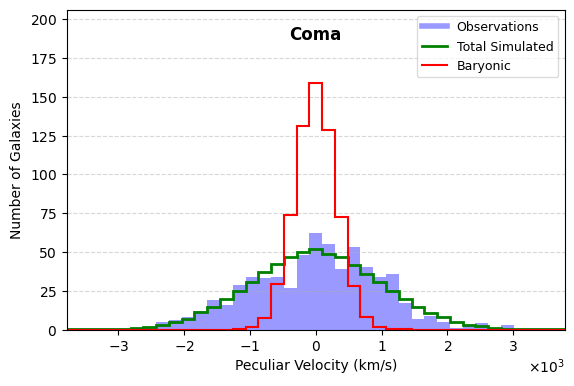

Cluster grid saved: cluster_plots_output/FINAL_Cluster_Grid.png


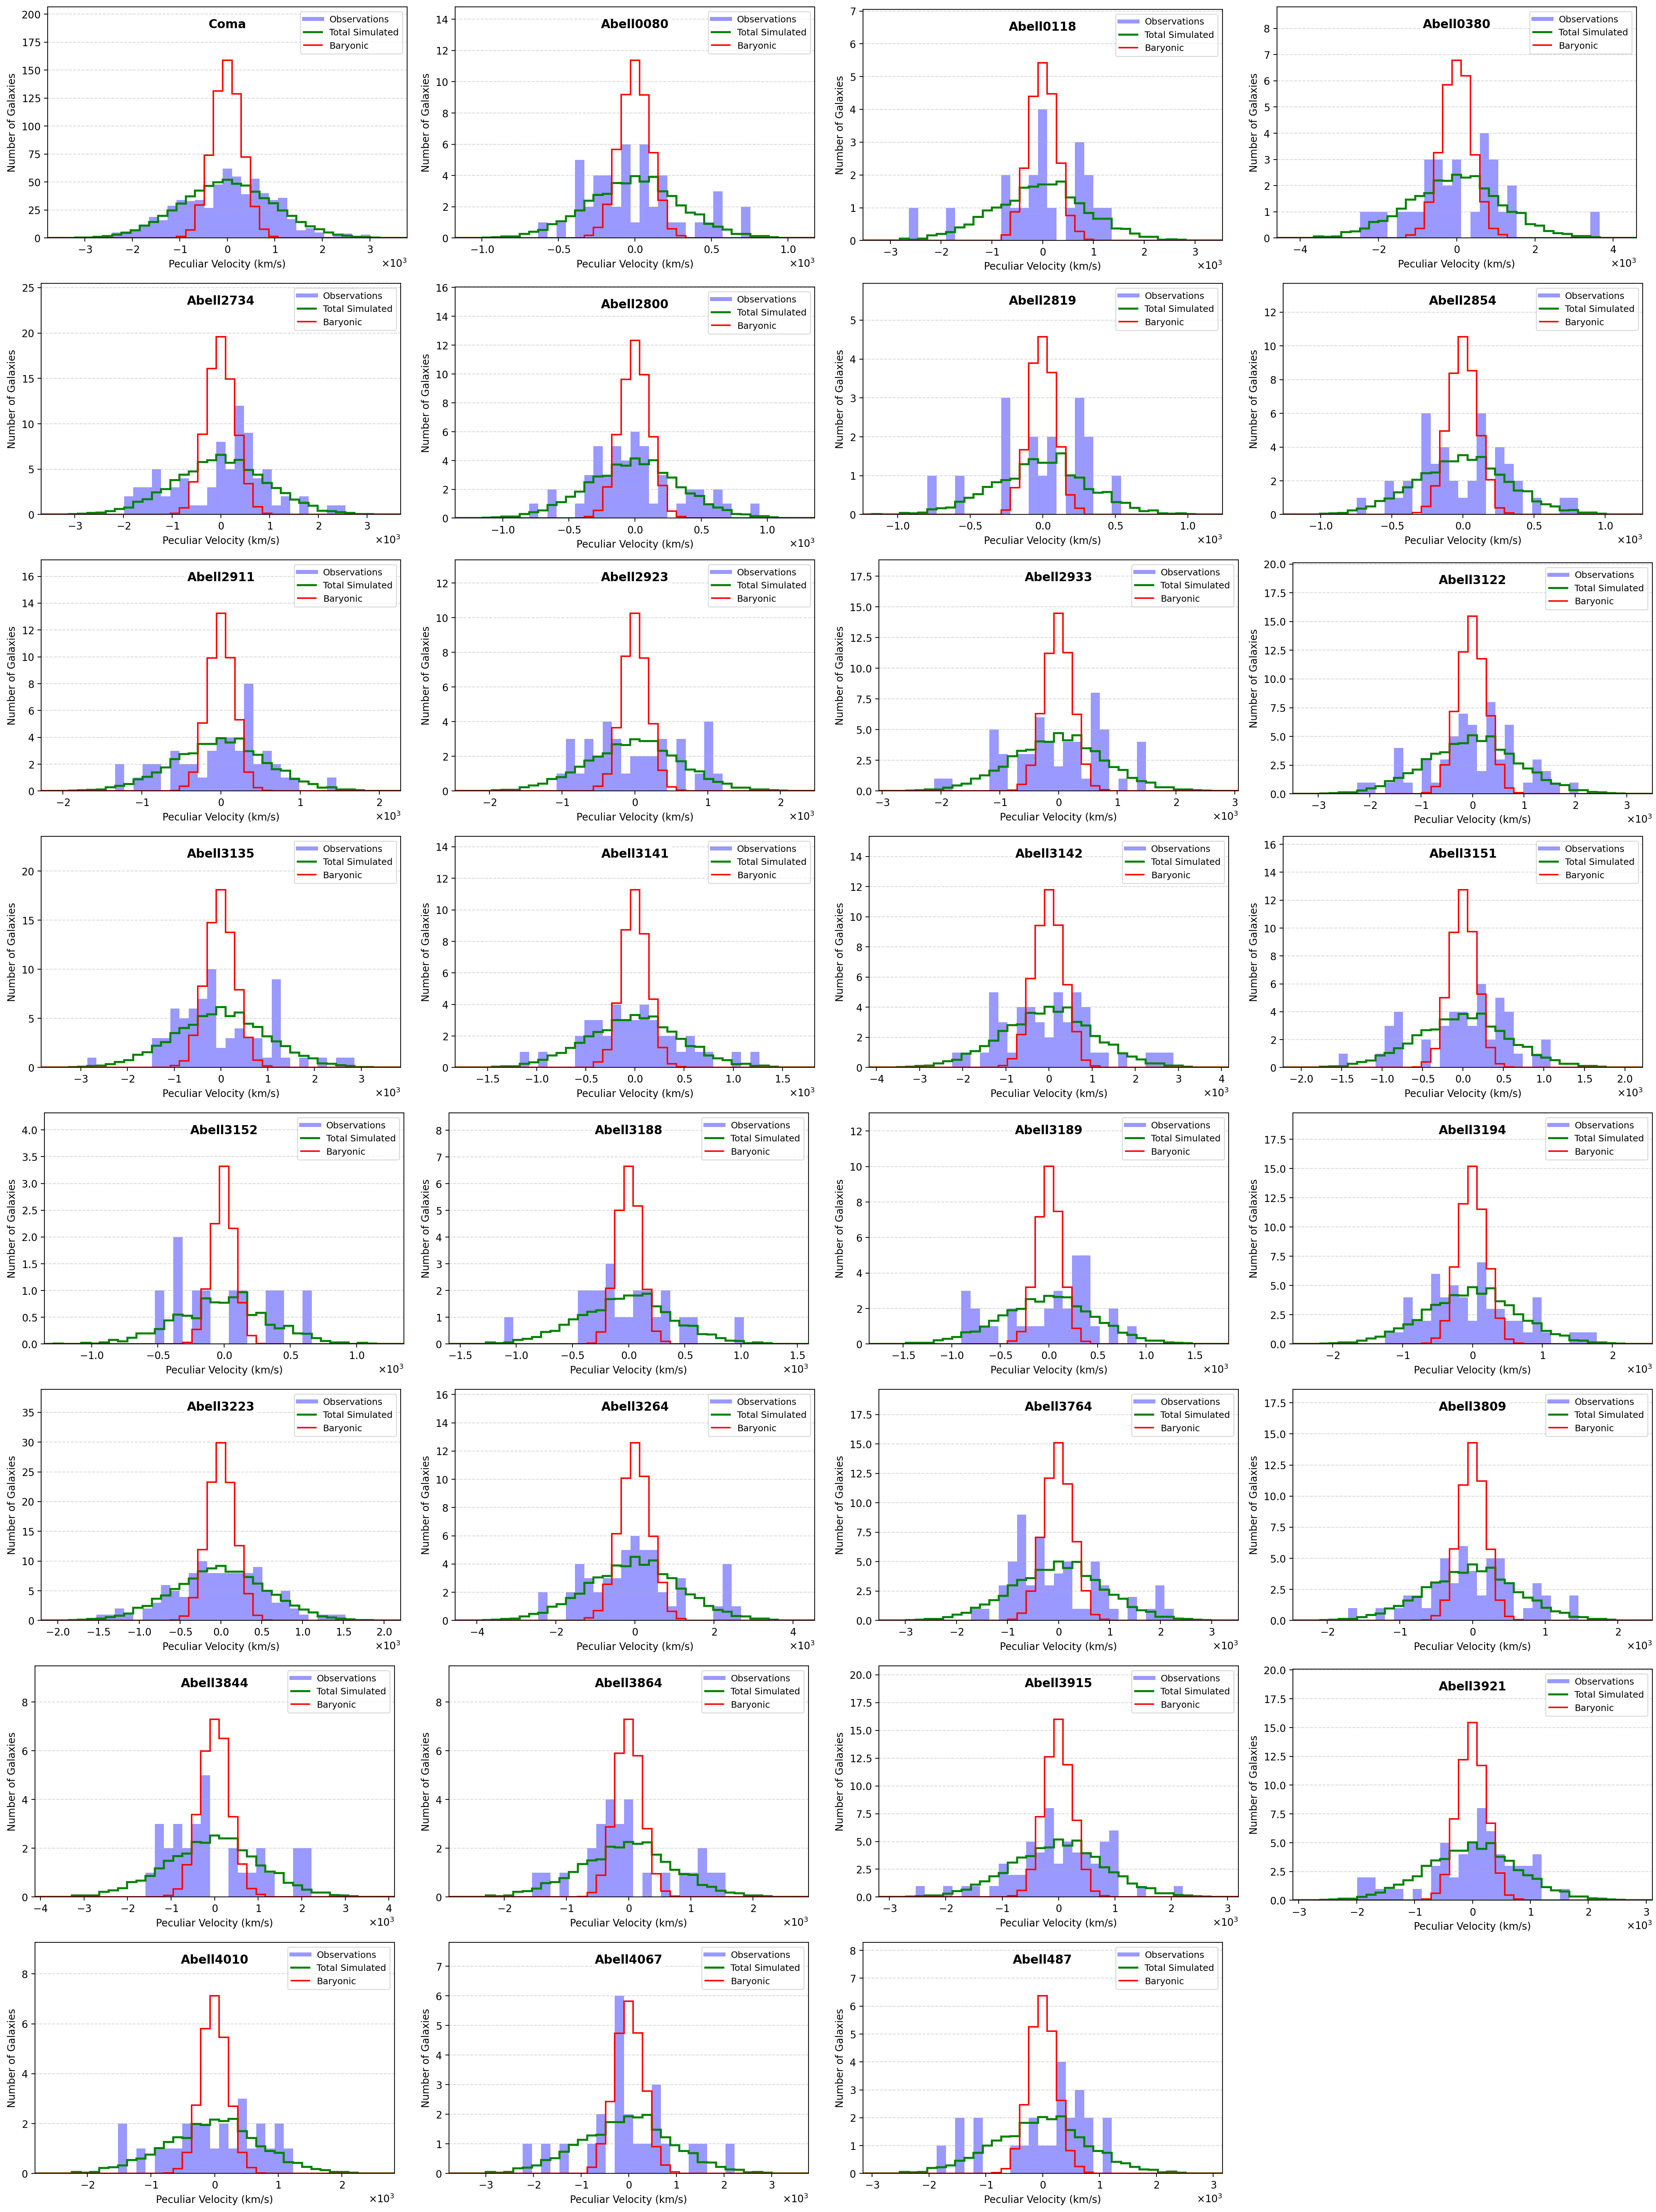

In [15]:
# ==============================================================================
# STEP 4: Peculiar Velocity Histograms, 100x Monte Carlo Oversampling, Chi2_nu & Grid
# Paper Reference: Main Paper Sec. 3.2, Eq. (16), Fig. 4; Supplementary Material Fig. S2
# Literature: Pearson (1900); Taylor (1997, Sec. 12.3, p. 269);
#             Barlow & Beeston (1993, Comput. Phys. Commun., 77, 219);
#             Hou et al. (2009, ApJ, 702, 1199)
# ==============================================================================
SHOW_INDIVIDUAL_PLOTS = False  # Set to True to display all 31 histograms inline
cluster_image_files = []
cluster_table_data = []

for cluster_name, cdata in valid_clusters.items():
    observed_vel = cdata["observed_vel"]
    scale_sim = cdata["sigma_global"]
    sigma_bar = cdata["sigma_bar"]
    display_name = cdata["display_name"]

    # 1. Peculiar line-of-sight velocities in the cluster rest frame (mean = 0)
    v_peculiar = observed_vel - np.mean(observed_vel)

    # 2. 100x Monte Carlo oversampling (weighted by 1/100) to suppress finite-sample
    #    fluctuations in the model template (Barlow & Beeston 1993; Main Paper Sec. 3.2 footnote)
    oversample = 100
    rng = np.random.default_rng(seed=42)
    v_sim_tot = rng.normal(loc=0.0, scale=scale_sim, size=len(v_peculiar) * oversample)
    v_bar = rng.normal(loc=0.0, scale=sigma_bar, size=len(v_peculiar) * oversample)

    # 3. Discretize velocity domain into 39 equally spaced bins (40 bin edges; Main Paper Sec. 3.2)
    max_abs = max(np.abs(v_peculiar).max(), 3.5 * scale_sim)
    x_lim = max_abs * 1.10
    bins = np.linspace(-x_lim, x_lim, 40)

    weights_sim = np.ones_like(v_sim_tot) / oversample
    weights_bar = np.ones_like(v_bar) / oversample

    obs_counts, _ = np.histogram(v_peculiar, bins=bins)
    sim_counts, _ = np.histogram(v_sim_tot, bins=bins, weights=weights_sim)
    bar_counts, _ = np.histogram(v_bar, bins=bins, weights=weights_bar)

    # 4. Reduced Binned Pearson's Chi-Square [Main Paper, Eq. (16); Pearson 1900]
    #    Evaluated over valid bins (E_i >= 0.5) with k = 3 constraints (N, mean, sigma; Taylor 1997)
    valid_bins = sim_counts >= 0.5
    if np.sum(valid_bins) > 3:
        chi2_raw = np.sum(((obs_counts[valid_bins] - sim_counts[valid_bins])**2) / sim_counts[valid_bins])
        dof = max(1, np.sum(valid_bins) - 3)
        chi2_nu = chi2_raw / dof
    else:
        chi2_nu = 0.0



    cluster_table_data.append({
        "Cluster": display_name,
        "M_tot": cdata["M_tot"],
        "DM_frac": cdata["DM_frac"],
        "Gas_frac": cdata["Gas_frac"],
        "Star_frac": cdata["Star_frac"],
        "chi2_nu": chi2_nu,
        "N_gal_final": cdata["n_gal_final"],
        "N_gal_initial": cdata["n_gal_initial"],

    })

    # --- Plot Individual Peculiar Velocity Histogram (Main Paper Fig. 4 / SM Fig. S2) ---
    fig, ax = plt.subplots(figsize=(6, 4))
    fig.subplots_adjust(top=0.92, bottom=0.12, left=0.12, right=0.95)

    # Proxy legend handles for crisp styling
    ax.plot([], [], color="blue", alpha=0.4, linewidth=4, label="Observations")
    ax.plot([], [], color="green", linewidth=2, label="Total Simulated")
    ax.plot([], [], color="red", linewidth=1.5, label="Baryonic")

    ax.hist(v_peculiar, bins=bins, alpha=0.4, color="blue")
    ax.hist(v_sim_tot, bins=bins, weights=weights_sim, histtype="step", linewidth=2, color="green")
    ax.hist(v_bar, bins=bins, weights=weights_bar, histtype="step", linewidth=1.5, color="red")

    ax.text(
        0.5, 0.95, display_name, transform=ax.transAxes,
        ha="center", va="top", fontsize=12, fontweight="bold",
        bbox=dict(facecolor="white", alpha=0.8, edgecolor="none", pad=2),
    )
    ax.set_xlabel("Peculiar Velocity (km/s)", fontsize=10)
    ax.set_ylabel("Number of Galaxies", fontsize=10)
    ax.set_ylim(0, max(obs_counts.max(), sim_counts.max(), bar_counts.max()) * 1.3)
    ax.set_xlim(-x_lim, x_lim)
    ax.legend(loc="upper right", fontsize=9, framealpha=0.7)
    ax.grid(True, axis="y", linestyle="--", alpha=0.5)
    ax.xaxis.set_major_formatter(ticker.ScalarFormatter(useMathText=True))
    ax.yaxis.set_major_formatter(ticker.ScalarFormatter(useMathText=True))
    ax.ticklabel_format(style="sci", axis="x", scilimits=(0, 0))

    plot_filename = os.path.join(OUTPUT_DIR, f"{cluster_name}_plot.png")
    plt.savefig(plot_filename, dpi=200, bbox_inches="tight")
    if SHOW_INDIVIDUAL_PLOTS or display_name == "Coma":
      plt.show()
    plt.close()

    cluster_image_files.append(plot_filename)

# Assemble and display the 4-column summary grid (Supplementary Material Fig. S2)
cluster_grid_path = create_grid(
    cluster_image_files,
    os.path.join(OUTPUT_DIR, "FINAL_Cluster_Grid.png"),
    cols=4,
)
if cluster_grid_path:
    display(IPyImage(filename=cluster_grid_path))

## Step 5: Dark Matter Fraction vs. Total Mass ($M_{200}$)

We visualize the mass-dependent composition trend across the 31 analyzed clusters (**Main Paper, Sec. 3.4, Fig. 5**). While Dark Matter consistently accounts for $\sim 89\text{--}94\%$ of the total mass, the hot gas fraction grows monotonically with $M_{200}$ ($M_{\text{gas}} \propto M_{200}^{1.21}$; Giodini et al., 2009) whereas the stellar fraction decreases, causing $\% M_{\text{DM}}$ to decline gently in the most massive clusters (Gonzalez et al., 2013).

Both a static Matplotlib figure and an interactive Plotly scatter plot are generated below.

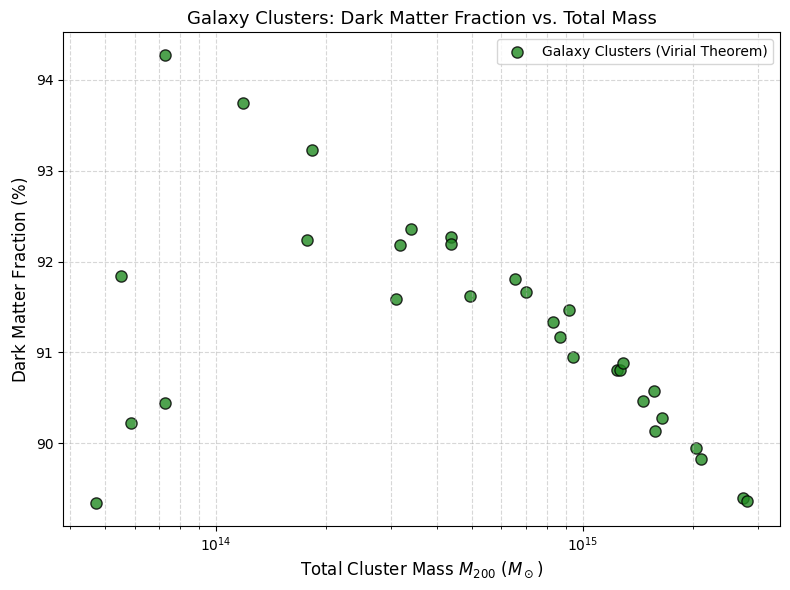

In [16]:
# ==============================================================================
# STEP 5: Dark Matter Fraction vs. Total Virial Mass (Static & Interactive)
# Paper Reference: Main Paper Sec. 3.4, Fig. 5
# Literature: Giodini et al. (2009, ApJ, 703, 982); Gonzalez et al. (2013, ApJ, 778, 14)
# ==============================================================================
df_cl_results = pd.DataFrame(cluster_table_data).sort_values("M_tot")

# 1. Static Matplotlib Scatter Plot (matching Main Paper Fig. 5)
plt.figure(figsize=(8, 6))
plt.scatter(
    df_cl_results["M_tot"], df_cl_results["DM_frac"],
    color="forestgreen", s=65, alpha=0.8, edgecolor="black",
    label="Galaxy Clusters (Virial Theorem)",
)
plt.xscale("log")
plt.xlabel(r"Total Cluster Mass $M_{200}$ ($M_\odot$)", fontsize=12)
plt.ylabel(r"Dark Matter Fraction ($\%$)", fontsize=12)
plt.title("Galaxy Clusters: Dark Matter Fraction vs. Total Mass", fontsize=13)
plt.legend()
plt.grid(True, which="both", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "clusters_DM_vs_Mtot_scatter.png"), dpi=300, bbox_inches="tight")
plt.show()

# 2. Interactive Plotly Scatter Plot (hover over points to inspect mass budget & fit quality)
fig_cl_plotly = px.scatter(
    df_cl_results,
    x="M_tot",
    y="DM_frac",
    hover_name="Cluster",
    hover_data={
        "Gas_frac": ":.2f",
        "Star_frac": ":.2f",
        "chi2_nu": ":.2f",
        "N_gal_final": True,
    },
    log_x=True,
    color_discrete_sequence=["forestgreen"],
    labels={
        "M_tot": "Total Cluster Mass M_200 (Solar Masses)",
        "DM_frac": "Dark Matter Fraction (%)",
    },
    title="Dark Matter Fraction vs. Total Mass — SARS & Coma Galaxy Clusters",
)
fig_cl_plotly.update_traces(marker=dict(size=12, line=dict(width=1, color="black"), opacity=0.85))
fig_cl_plotly.update_layout(title_font_size=16, xaxis_title_font_size=13, yaxis_title_font_size=13)
fig_cl_plotly.write_html(os.path.join(OUTPUT_DIR, "clusters_DM_vs_Mtot_scatter_plotly.html"))
fig_cl_plotly.show()

## Step 6: Export Supplementary Material Table (SM Table S2)

Finally, we sort the 31 clusters by increasing total virial mass $M_{200}$ and export the complete LaTeX table reporting total mass, mass fractions ($\% M_{\text{DM}}$, $\% M_{\text{gas}}$, $\% M_{\text{star}}$), reduced chi-square ($\chi^2_\nu$), and retained galaxy counts ($N_{\text{gal}}$), reproducing **Table S2** of the Supplementary Material.

In [17]:
# ==============================================================================
# STEP 6: Generate Supplementary Material LaTeX Table (SM Table S2)
# Reference: SupplementaryMaterial.tex, Sec. S2, Tab. S2 (tab:clusters_mass_budget)
# ==============================================================================
sorted_clusters = sorted(cluster_table_data, key=lambda x: x["M_tot"])

lines = [
    r"\begin{table}[H]",
    r"\centering",
    r"{\small \setlength{\tabcolsep}{8pt}",
    r"\begin{tabular}{lcccccc}",
    r"\hline",
    r"\textbf{Cluster} & \textbf{$M_{\text{tot}} \ [M_\odot]$} & \textbf{$\% M_{\text{DM}}$} & \textbf{$\% M_{\text{gas}}$} & \textbf{$\% M_{\text{star}}$} & \textbf{$\chi^2_{\nu}$} & \textbf{$N_{gal}$} \\",
    r"\hline",
]

for row in sorted_clusters:
    m_tot = row["M_tot"]
    exp = int(np.floor(np.log10(m_tot)))
    coef = m_tot / (10**exp)
    if round(coef, 2) >= 10.0:
        coef /= 10.0
        exp += 1
    m_tot_str = f"${coef:.2f} \\times 10^{{{exp}}}$"

    lines.append(
        f"{row['Cluster']:<9} & {m_tot_str} & "
        f"{row['DM_frac']:.2f}\\% & {row['Gas_frac']:.2f}\\% & {row['Star_frac']:.2f}\\% & "
        f"{row['chi2_nu']:.2f} & {int(row['N_gal_final'])}/{int(row['N_gal_initial'])} \\\\"
    )

lines.extend([
    r"\hline",
    r"\end{tabular}}",
    r"\caption{Mass budget, fit quality and retained galaxies count for the analyzed cluster sample.}",
    r"\label{tab:clusters_mass_budget}",
    r"\end{table}",
])

cl_latex_output = "\n".join(lines)
print(cl_latex_output)

cl_tex_path = os.path.join(OUTPUT_DIR, "clusters_mass_budget_table.tex")
with open(cl_tex_path, "w", encoding="utf-8") as f:
    f.write(cl_latex_output)
print(f"\nLaTeX table saved to: {cl_tex_path}")



\begin{table}[H]
\centering
{\small \setlength{\tabcolsep}{8pt}
\begin{tabular}{lcccccc}
\hline
\textbf{Cluster} & \textbf{$M_{\text{tot}} \ [M_\odot]$} & \textbf{$\% M_{\text{DM}}$} & \textbf{$\% M_{\text{gas}}$} & \textbf{$\% M_{\text{star}}$} & \textbf{$\chi^2_{\nu}$} & \textbf{$N_{gal}$} \\
\hline
Abell0080 & $4.70 \times 10^{13}$ & 89.34\% & 4.46\% & 6.20\% & 1.58 & 47/107 \\
Abell2819 & $5.52 \times 10^{13}$ & 91.84\% & 4.61\% & 3.55\% & 1.66 & 17/47 \\
Abell2854 & $5.86 \times 10^{13}$ & 90.22\% & 4.67\% & 5.11\% & 1.32 & 42/105 \\
Abell3152 & $7.25 \times 10^{13}$ & 94.27\% & 4.88\% & 0.85\% & 1.18 & 10/53 \\
Abell2800 & $7.29 \times 10^{13}$ & 90.45\% & 4.89\% & 4.66\% & 0.92 & 49/119 \\
Abell3188 & $1.19 \times 10^{14}$ & 93.74\% & 5.41\% & 0.85\% & 0.58 & 22/46 \\
Abell3141 & $1.77 \times 10^{14}$ & 92.24\% & 5.89\% & 1.87\% & 0.38 & 40/96 \\
Abell3189 & $1.83 \times 10^{14}$ & 93.23\% & 5.93\% & 0.84\% & 1.75 & 33/85 \\
Abell3223 & $3.10 \times 10^{14}$ & 91.59\% & 6.62\% &